Apriori Algorithm and Analysis for question 2

In [2]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

In [3]:
#load dataset
df=pd.read_csv('archive (3)/low_reordered_basket.csv', 
                  quotechar='"', 
                  on_bad_lines='skip', 
                  engine='python')



In [4]:
#Encoding và Apriori trên giỏ hàng
transactions = df.groupby('order_id')['product_name'].apply(list).to_list()
te = TransactionEncoder()
te_data = te.fit(transactions).transform(transactions, sparse=True)
transaction_encoded = pd.DataFrame.sparse.from_spmatrix(te_data, columns=te.columns_)

min_support = 0.002 # chọn ngưỡng min support phải đạt 0,2% trên tổng đơn hàng
frequent_itemsets = apriori(transaction_encoded, min_support, use_colnames=True, low_memory=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)
results = rules.sort_values('lift', ascending=False)

In [5]:
# Load danh sách các sản phẩm được reordered thấp
low_df = pd.read_csv('archive (3)/low_reordered_products.csv', quotechar='"',
                     on_bad_lines='skip', engine='python')
low_set = set(low_df['product_name'].str.strip())

#Luật 1 → 1
pairs = results[(results['antecedents'].apply(len) == 1) &
                (results['consequents'].apply(len) == 1)].copy()
pairs['A'] = pairs['antecedents'].apply(lambda s: next(iter(s)))
pairs['B'] = pairs['consequents'].apply(lambda s: next(iter(s)))

15


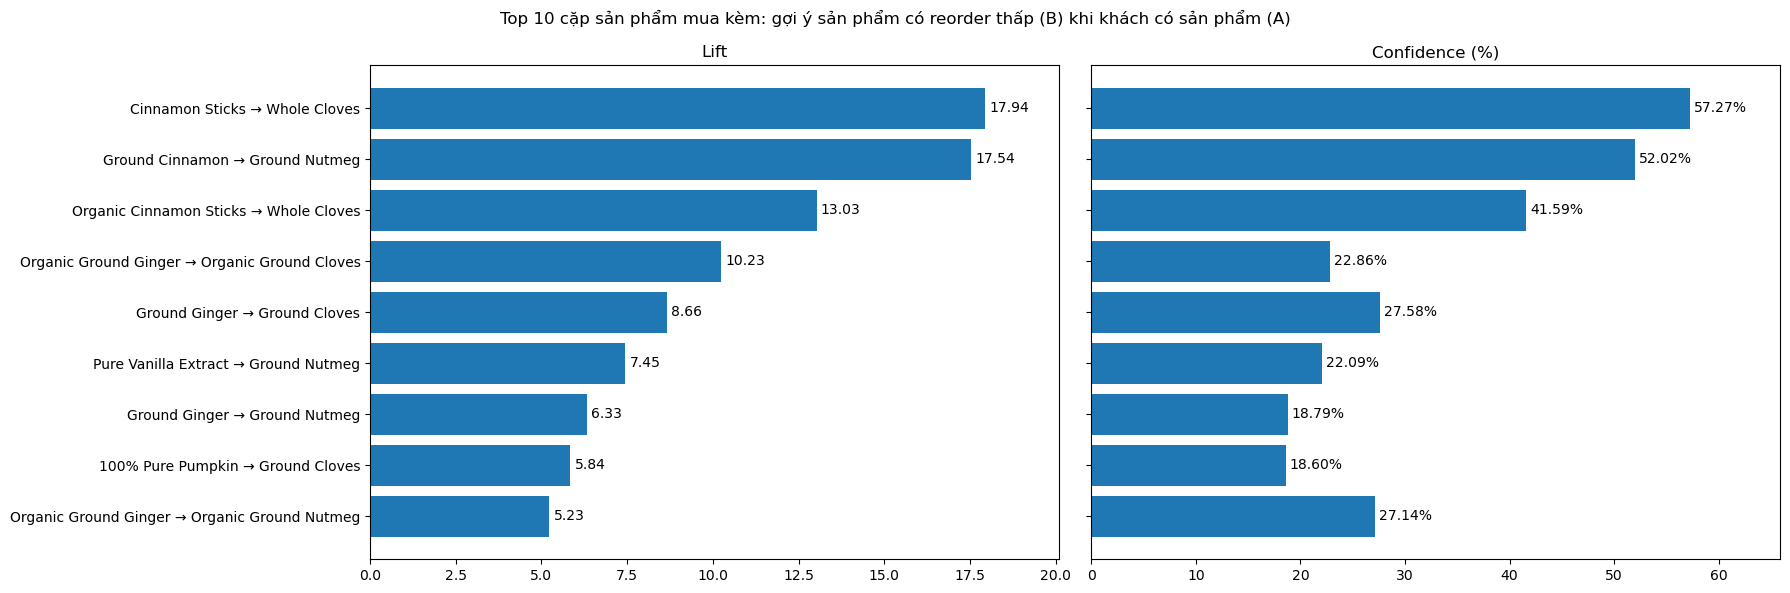

In [6]:
import matplotlib.pyplot as plt
#Luật gợi ý: B là sản phẩm reorder thấp, A là sản phẩm khác
LIFT_MIN, CONF_MIN = 2, 0.15
rules_q2 = pairs[pairs['B'].isin(low_set) & ~pairs['A'].isin(low_set)].copy()
rules_q2 = rules_q2[(rules_q2['lift'] >= LIFT_MIN) & (rules_q2['confidence'] >= CONF_MIN)]
rules_q2['goi_y'] = rules_q2['A'] + ' → ' + rules_q2['B']
print(len(rules_q2))        # so với số cặp em đưa vào bảng Recommendation

#Chart 1: lift và confidence của các cặp mua kèm ---
top = rules_q2.sort_values('lift', ascending=False).head(9).iloc[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

ax1.barh(top['goi_y'], top['lift'])
ax1.set_title('Lift')
ax1.bar_label(ax1.containers[0], fmt='%.2f', padding=3)
ax1.margins(x=0.12)

ax2.barh(top['goi_y'], top['confidence'] * 100)
ax2.set_title('Confidence (%)')
ax2.bar_label(ax2.containers[0], fmt='%.2f%%', padding=3)
ax2.margins(x=0.15)

plt.suptitle('Top 10 cặp sản phẩm mua kèm: gợi ý sản phẩm có reorder thấp (B) khi khách có sản phẩm (A)')
plt.tight_layout()
plt.savefig('q2_pairs.png', dpi=200, bbox_inches='tight')
plt.show()

In [7]:
# Bảng Top các cặp sản phẩm gợi ý B (Có reorder thấp) khi đã mua A
top.sort_values('lift',ascending=False)
top.round(4).to_csv("top_q2.csv", index=False, encoding="utf-8-sig")

In [8]:
#Độ bao phủ (tính trên toàn bộ luật)
LIFT_MIN, CONF_MIN = 2, 0.15
def covered_all(rules_df):
    items = set()
    for s in rules_df['antecedents']: items |= set(s)
    for s in rules_df['consequents']: items |= set(s)
    return items & low_set

has_strong = covered_all(results[(results['lift'] >= LIFT_MIN) & (results['confidence'] >= CONF_MIN)])
has_any = covered_all(results)

#Chia nhóm A/B/C
q25, med = low_df['total_purchase'].quantile([0.25, 0.5])
base = low_df[low_df['product_name'].isin(low_set - has_strong)].copy()
base['nhom'] = base['total_purchase'].apply(
    lambda n: 'A_can_nhac_loai_bo' if n <= q25 else ('B_doi_chieu_doanh_thu' if n >= med else 'C_theo_doi'))
print(len(low_set), len(has_strong), base['nhom'].value_counts())

127 13 nhom
B_doi_chieu_doanh_thu    51
A_can_nhac_loai_bo       33
C_theo_doi               30
Name: count, dtype: int64


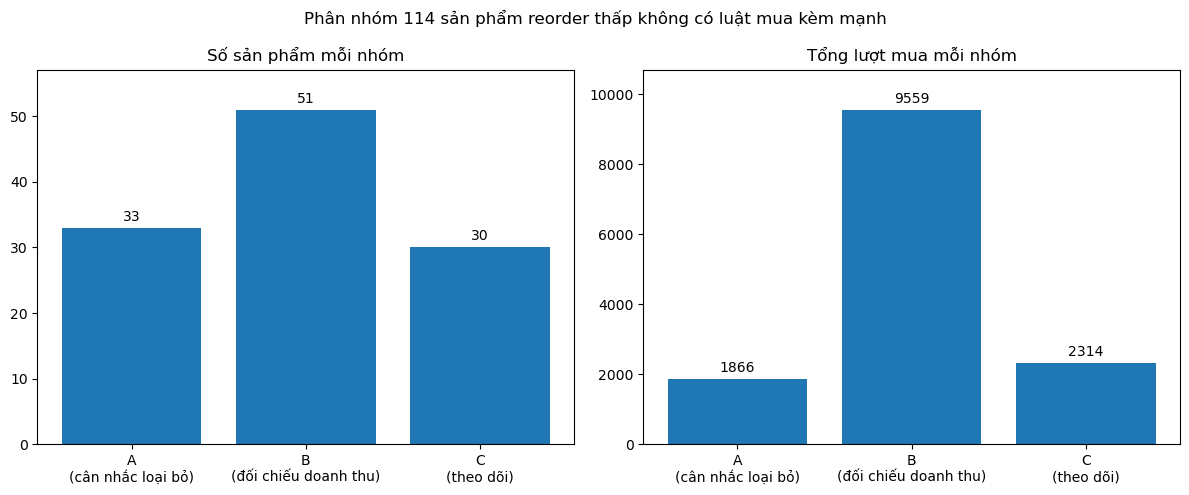

In [9]:
#Chart 2: phân nhóm sản phẩm reorder thấp không có luật mạnh
g = base.groupby('nhom')['total_purchase'].agg(['count', 'sum'])
g.index = ['A\n(cân nhắc loại bỏ)', 'B\n(đối chiếu doanh thu)', 'C\n(theo dõi)']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(g.index, g['count'])
ax1.set_title('Số sản phẩm mỗi nhóm')
ax1.bar_label(ax1.containers[0], padding=3)
ax1.margins(y=0.12)

ax2.bar(g.index, g['sum'])
ax2.set_title('Tổng lượt mua mỗi nhóm')
ax2.bar_label(ax2.containers[0], fmt='%d', padding=3)
ax2.margins(y=0.12)

plt.suptitle('Phân nhóm 114 sản phẩm reorder thấp không có luật mua kèm mạnh')
plt.tight_layout()
plt.savefig('q2_groups.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
#Top 10 các sản phẩm nhóm A
top_10_A=base[base['nhom']=='A_can_nhac_loai_bo'].sort_values('reorder_rate',ascending=False).head(10)

In [11]:
top_10_A.round(4).to_csv("top_10_A.csv", index=False, encoding="utf-8-sig")

In [12]:
base.round(4).to_csv("base.csv", index=False, encoding="utf-8-sig")

In [23]:
low_df.round(4).to_csv("low_df.csv", index=False, encoding="utf-8-sig")

In [20]:
strong_df=results[(results['lift'] >= LIFT_MIN) & (results['confidence'] >= CONF_MIN)]

In [21]:
len(strong_df)

1204

In [22]:
low_df

,product_name,total_purchase,total_reordered,reorder_rate
0,Naturally Nutritious Organic Savory Herb Stuffing,146,7,0.047945
1,Classic Seasoned Dressing Mix,50,2,0.040000
2,Organic Ground Mustard,112,3,0.026786
3,Organic Poppy Seed,224,7,0.031250
4,Whole Celery Seed,233,7,0.030043
...,...,...,...,...
122,Ground Mustard,313,7,0.022364
123,Baking Cups,121,6,0.049587
124,Ground Cardamom,422,17,0.040284
125,Rosemary Volumizing Conditioner,51,2,0.039216


In [24]:
strong = low_df[low_df['product_name'].isin(has_strong)].copy()

In [26]:
strong.round(4).to_csv("strong.csv", index=False, encoding="utf-8-sig")